<a href="https://colab.research.google.com/github/haneesh-n/Thiranex-Data-Science-Internship/blob/main/Task%202%20%E2%80%94%20Predictive%20Modeling%20Using%20Machine%20Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 2 — Predictive Modeling Using Machine Learning
**Thiranex Data Science Internship**

## Project: Titanic Passenger Survival Prediction
**Objective:** Train and evaluate supervised ML classifiers to predict passenger survival from historical Titanic passenger data.

Dataset: public Seaborn Titanic CSV. Educational project only.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, RocCurveDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


## 2. Load and inspect dataset

In [2]:
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df = pd.read_csv(DATA_URL)
print("Dataset shape:", df.shape)
display(df.head())
display(df.isna().sum().sort_values(ascending=False).to_frame("missing values"))
display(df.describe(include="all").T)


Dataset shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


,missing values
deck,688
age,177
embarked,2
embark_town,2
sex,0
pclass,0
survived,0
fare,0
parch,0
sibsp,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


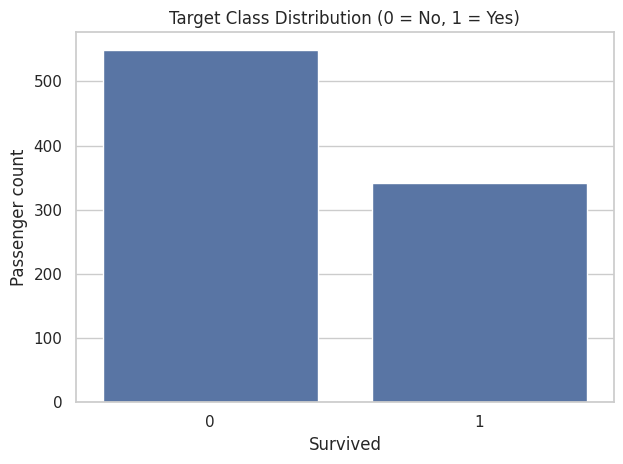

In [3]:
sns.countplot(data=df, x="survived")
plt.title("Target Class Distribution (0 = No, 1 = Yes)")
plt.xlabel("Survived")
plt.ylabel("Passenger count")
plt.tight_layout()
plt.show()


## 3. Prepare features and split data
Exclude `alive`, which duplicates the target, to prevent target leakage. Imputation and encoding are fit only on training data.

In [4]:
features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
X = df[features].copy()
y = df["survived"].astype(int)
numeric_features = ["pclass", "age", "sibsp", "parch", "fare"]
categorical_features = ["sex", "embarked"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))


Training rows: 712 | Test rows: 179


## 4. Build preprocessing pipeline

In [5]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])


## 5. Train models

In [6]:
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced"
        ))
    ])
}
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained")


Logistic Regression trained
Random Forest trained


## 6. Evaluate performance

In [7]:
rows = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })
metrics = pd.DataFrame(rows).set_index("Model").round(3)
display(metrics)


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.804,0.793,0.667,0.724,0.844
Random Forest,0.816,0.800,0.696,0.744,0.828


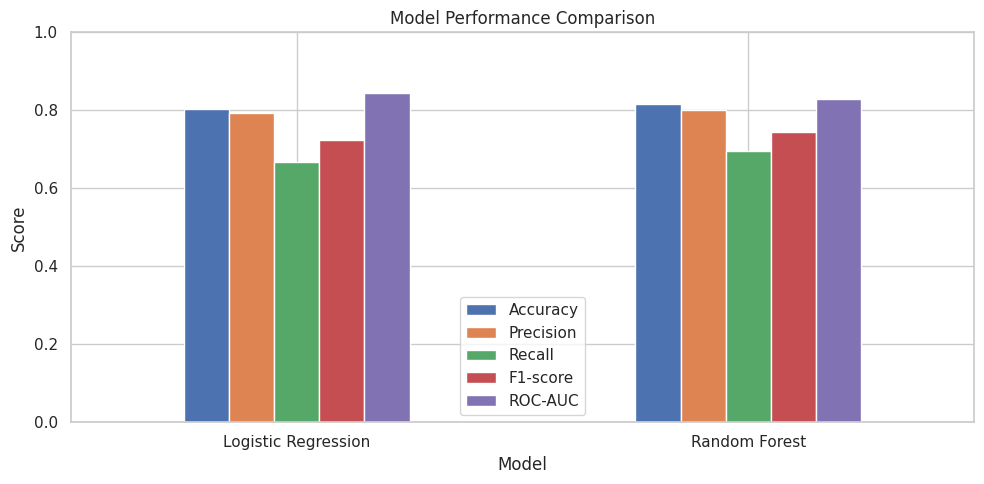

In [8]:
metrics.plot(kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.tight_layout()
plt.show()


## 7. Confusion matrices and classification reports

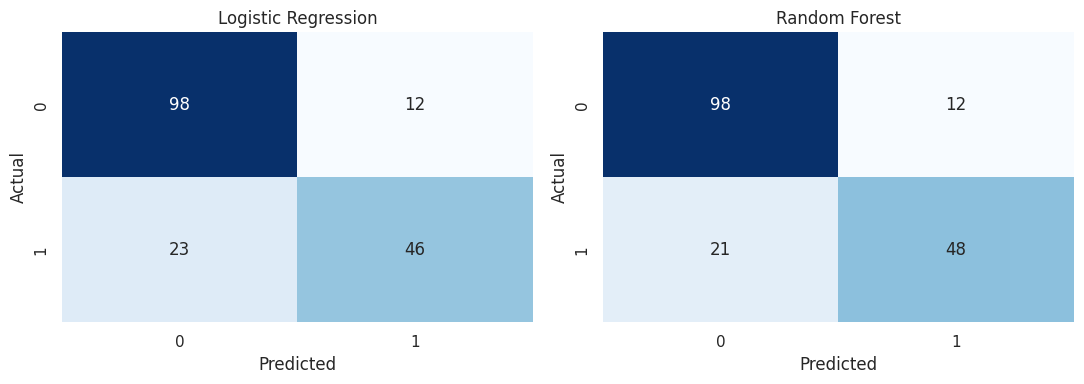

\n Logistic Regression
                 precision    recall  f1-score   support

Did not survive       0.81      0.89      0.85       110
       Survived       0.79      0.67      0.72        69

       accuracy                           0.80       179
      macro avg       0.80      0.78      0.79       179
   weighted avg       0.80      0.80      0.80       179

\n Random Forest
                 precision    recall  f1-score   support

Did not survive       0.82      0.89      0.86       110
       Survived       0.80      0.70      0.74        69

       accuracy                           0.82       179
      macro avg       0.81      0.79      0.80       179
   weighted avg       0.81      0.82      0.81       179



In [9]:
fig, axes = plt.subplots(1, len(models), figsize=(11, 4))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

for name, model in models.items():
    print("\\n", name)
    print(classification_report(y_test, model.predict(X_test),
          target_names=["Did not survive", "Survived"]))


## 8. ROC curves

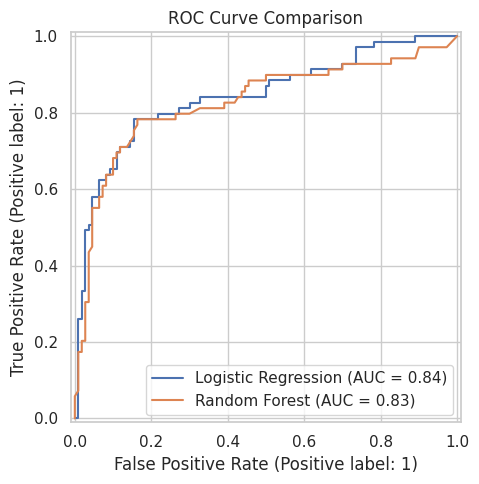

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.set_title("ROC Curve Comparison")
plt.tight_layout()
plt.show()


## 9. Save the best model and metrics

In [11]:
best_name = metrics["F1-score"].idxmax()
best_model = models[best_name]
print("Best model by test F1-score:", best_name)

Path("outputs").mkdir(exist_ok=True)
joblib.dump(best_model, "outputs/titanic_survival_model.joblib")
metrics.to_csv("outputs/model_metrics.csv")
print("Saved outputs/model and outputs/model_metrics.csv")


Best model by test F1-score: Random Forest
Saved outputs/model and outputs/model_metrics.csv


## 10. Example prediction
This is a demonstration only; a prediction is not a certainty.

In [12]:
example = pd.DataFrame([{
    "pclass": 3, "sex": "female", "age": 25,
    "sibsp": 0, "parch": 0, "fare": 8.05, "embarked": "S"
}])
prediction = int(best_model.predict(example)[0])
probability = float(best_model.predict_proba(example)[0, 1])
print("Prediction:", "Survived" if prediction else "Did not survive")
print(f"Estimated probability: {probability:.1%}")


Prediction: Did not survive
Estimated probability: 29.3%


## 11. Limitations
- This is a small historical dataset and may not generalize beyond its context.
- Reported metrics depend on this train/test split.
- Cross-validation and external validation could provide more robust evaluation.
- Model predictions are statistical estimates, not causal conclusions.